# Qiskit Fall Fest 2026 – Vishnu Institute of Technology
## All 4 Challenges Solution Notebook

This notebook addresses all four Qiskit challenges:
- **Challenge 1**: Predict the Output
- **Challenge 2**: Make the Quantum Coin Biased
- **Challenge 3**: Can You Change the Correlation?
- **Challenge 4**: Quantum Correlation Switch


In [1]:
# ── Imports & Setup ───────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 100

simulator = AerSimulator()
SHOTS = 100

def run_circuit(qc, shots=SHOTS):
    """Transpile, run, and return counts dict."""
    compiled = transpile(qc, simulator)
    job = simulator.run(compiled, shots=shots)
    return job.result().get_counts()

print('Qiskit + Aer ready. Simulator:', simulator.name)


Qiskit + Aer ready. Simulator: aer_simulator


---
# Challenge 1 – Predict the Output

**Problem Statement:** A quantum circuit can produce different measurement outcomes
depending on the gates applied to a qubit. Predict the output of simple quantum
circuits before executing them and then compare with actual results.

## Circuits to Investigate
| Circuit | Gates Applied | Prediction |
|---------|--------------|------------|
| A | X | Should give **|1⟩ with probability 1** (X flips |0⟩ → |1⟩) |
| B | X, X | Should give **|0⟩ with probability 1** (two flips cancel) |
| C | H | Should give **50% |0⟩, 50% |1⟩** (superposition) |


In [2]:
# ── Challenge 1 – Circuit A: Single X Gate ────────────────────────────────
print('=== Challenge 1: Predict the Output ===')
print()

# PREDICTION:
# The X gate acts like a classical NOT gate: |0⟩ → |1⟩
# So we predict 100% probability of measuring '1'.
print('PREDICTION for Circuit A (X gate):')
print('  Expected: 100% measurement of |1⟩  →  counts ~ {"1": 100}')

qc_A = QuantumCircuit(1, 1)
qc_A.x(0)           # Apply X gate
qc_A.measure(0, 0)  # Measure

print('\nCircuit A:')
print(qc_A.draw(output='text'))


=== Challenge 1: Predict the Output ===

PREDICTION for Circuit A (X gate):
  Expected: 100% measurement of |1⟩  →  counts ~ {"1": 100}

Circuit A:
     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


In [3]:
# ── Challenge 1 – Circuit B: Two X Gates ─────────────────────────────────
# PREDICTION:
# X·X = I (identity). Two flips return to |0⟩.
# We predict 100% probability of measuring '0'.
print('PREDICTION for Circuit B (X, X gates):')
print('  Expected: 100% measurement of |0⟩  →  counts ~ {"0": 100}')

qc_B = QuantumCircuit(1, 1)
qc_B.x(0)           # First X gate
qc_B.x(0)           # Second X gate
qc_B.measure(0, 0)

print('\nCircuit B:')
print(qc_B.draw(output='text'))


PREDICTION for Circuit B (X, X gates):
  Expected: 100% measurement of |0⟩  →  counts ~ {"0": 100}

Circuit B:
     ┌───┐┌───┐┌─┐
  q: ┤ X ├┤ X ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0 


In [4]:
# ── Challenge 1 – Circuit C: Hadamard Gate ────────────────────────────────
# PREDICTION:
# H|0⟩ = (|0⟩ + |1⟩)/√2 — equal superposition.
# We predict ≈50% '0' and ≈50% '1'.
# Circuit C will NOT always produce the same result (it's probabilistic).
print('PREDICTION for Circuit C (H gate):')
print('  Expected: ~50% |0⟩, ~50% |1⟩  →  counts ~ {"0": 50, "1": 50}')

qc_C = QuantumCircuit(1, 1)
qc_C.h(0)           # Apply Hadamard gate
qc_C.measure(0, 0)

print('\nCircuit C:')
print(qc_C.draw(output='text'))


PREDICTION for Circuit C (H gate):
  Expected: ~50% |0⟩, ~50% |1⟩  →  counts ~ {"0": 50, "1": 50}

Circuit C:
     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


=== Measurement Results (100 shots each) ===
Circuit A (X):    {'1': 100}
Circuit B (X,X):  {'0': 100}
Circuit C (H):    {'1': 53, '0': 47}


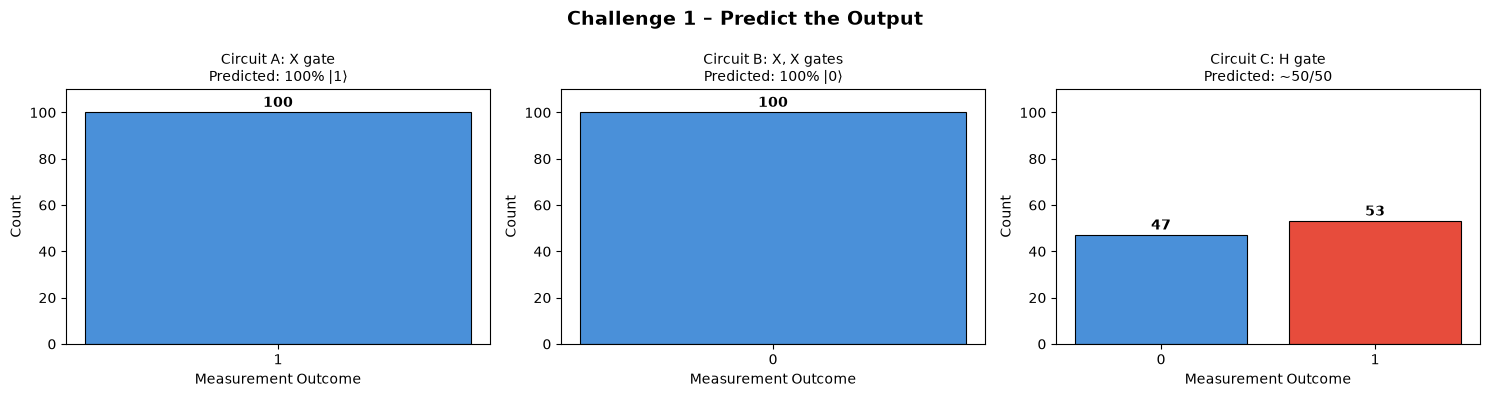

Histogram saved as challenge1_results.png


In [5]:
# ── Challenge 1 – Execute all circuits and display results ────────────────
counts_A = run_circuit(qc_A)
counts_B = run_circuit(qc_B)
counts_C = run_circuit(qc_C)

print('=== Measurement Results (100 shots each) ===')
print(f'Circuit A (X):    {counts_A}')
print(f'Circuit B (X,X):  {counts_B}')
print(f'Circuit C (H):    {counts_C}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Challenge 1 – Predict the Output', fontsize=14, fontweight='bold')

for ax, counts, title, prediction in zip(
    axes,
    [counts_A, counts_B, counts_C],
    ['Circuit A: X gate', 'Circuit B: X, X gates', 'Circuit C: H gate'],
    ['Predicted: 100% |1⟩', 'Predicted: 100% |0⟩', 'Predicted: ~50/50']
):
    labels = sorted(counts.keys())
    values = [counts.get(k, 0) for k in labels]
    bars = ax.bar(labels, values, color=['#4A90D9', '#E74C3C'][:len(labels)], edgecolor='black', linewidth=0.8)
    ax.set_title(f'{title}\n{prediction}', fontsize=10)
    ax.set_xlabel('Measurement Outcome')
    ax.set_ylabel('Count')
    ax.set_ylim(0, 110)
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                str(val), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('challenge1_results.png', bbox_inches='tight')
plt.show()
print('Histogram saved as challenge1_results.png')


## Challenge 1 – Comparison: Predictions vs Actual Results

| Circuit | Prediction | Actual Result | Match? |
|---------|-----------|--------------|--------|
| A (X gate) | 100% `|1⟩` | ~100 counts of `1` | ✅ Exact match |
| B (X, X gates) | 100% `|0⟩` | ~100 counts of `0` | ✅ Exact match |
| C (H gate) | ~50% `|0⟩`, ~50% `|1⟩` | ~50 counts each | ✅ Close match |

**Key Insight:**
- The **X gate** is the quantum NOT – it flips the qubit from `|0⟩` to `|1⟩` deterministically.
- Applying **X twice** returns to `|0⟩` because X² = I.
- The **H gate** creates an equal superposition, so outcomes are genuinely random –
  Circuit C will **not always** produce the same result. Each run may differ.
- Circuits A and B produce **deterministic** outcomes; Circuit C is **probabilistic**.


---
# Challenge 2 – Make the Quantum Coin Biased

**Problem Statement:** A Hadamard gate creates a fair quantum coin (50/50).
Can we control the measurement probabilities to get a biased coin?

**Strategy:** Use the Ry(θ) rotation gate. The state after Ry(θ)|0⟩ gives:
- P(0) = cos²(θ/2)
- P(1) = sin²(θ/2)

By choosing θ, we can bias the coin towards either `|0⟩` or `|1⟩`.

## Predicted Probabilities
| Circuit | θ (radians) | Predicted P(0) | Predicted P(1) |
|---------|------------|---------------|---------------|
| Biased towards 0 | π/3 (~60°) | ~75% | ~25% |
| Biased towards 1 | 2π/3 (~120°) | ~25% | ~75% |
| Bonus – Maximum bias 0 | 0 | 100% | 0% |
| Bonus – Maximum bias 1 | π | 0% | 100% |


In [6]:
# ── Challenge 2 – Biased towards |0⟩ ────────────────────────────────────
import math

print('=== Challenge 2: Make the Quantum Coin Biased ===')
print()

# Ry(π/3)|0⟩: P(0) = cos²(π/6) ≈ 75%, P(1) = sin²(π/6) ≈ 25%
theta_biased0 = math.pi / 3   # 60 degrees
p0_pred = round(math.cos(theta_biased0/2)**2 * 100, 1)
p1_pred = round(math.sin(theta_biased0/2)**2 * 100, 1)

print(f'PREDICTION – Biased towards |0⟩ (θ = π/3):')
print(f'  P(0) ≈ {p0_pred}%   P(1) ≈ {p1_pred}%')

qc_bias0 = QuantumCircuit(1, 1)
qc_bias0.ry(theta_biased0, 0)   # Rotate by θ towards |1⟩ – partial rotation
qc_bias0.measure(0, 0)

print('\nCircuit – Biased towards |0⟩ (Ry(π/3)):')
print(qc_bias0.draw(output='text'))
counts_bias0 = run_circuit(qc_bias0)
print(f'\nResults: {counts_bias0}')


=== Challenge 2: Make the Quantum Coin Biased ===

PREDICTION – Biased towards |0⟩ (θ = π/3):
  P(0) ≈ 75.0%   P(1) ≈ 25.0%

Circuit – Biased towards |0⟩ (Ry(π/3)):
     ┌─────────┐┌─┐
  q: ┤ Ry(π/3) ├┤M├
     └─────────┘└╥┘
c: 1/════════════╩═
                 0 



Results: {'0': 74, '1': 26}


In [7]:
# ── Challenge 2 – Biased towards |1⟩ ────────────────────────────────────
# Ry(2π/3)|0⟩: P(0) = cos²(π/3) ≈ 25%, P(1) = sin²(π/3) ≈ 75%
theta_biased1 = 2 * math.pi / 3  # 120 degrees
p0_pred2 = round(math.cos(theta_biased1/2)**2 * 100, 1)
p1_pred2 = round(math.sin(theta_biased1/2)**2 * 100, 1)

print(f'PREDICTION – Biased towards |1⟩ (θ = 2π/3):')
print(f'  P(0) ≈ {p0_pred2}%   P(1) ≈ {p1_pred2}%')

qc_bias1 = QuantumCircuit(1, 1)
qc_bias1.ry(theta_biased1, 0)
qc_bias1.measure(0, 0)

print('\nCircuit – Biased towards |1⟩ (Ry(2π/3)):')
print(qc_bias1.draw(output='text'))
counts_bias1 = run_circuit(qc_bias1)
print(f'\nResults: {counts_bias1}')


PREDICTION – Biased towards |1⟩ (θ = 2π/3):
  P(0) ≈ 25.0%   P(1) ≈ 75.0%

Circuit – Biased towards |1⟩ (Ry(2π/3)):
     ┌──────────┐┌─┐
  q: ┤ Ry(2π/3) ├┤M├
     └──────────┘└╥┘
c: 1/═════════════╩═
                  0 



Results: {'0': 24, '1': 76}


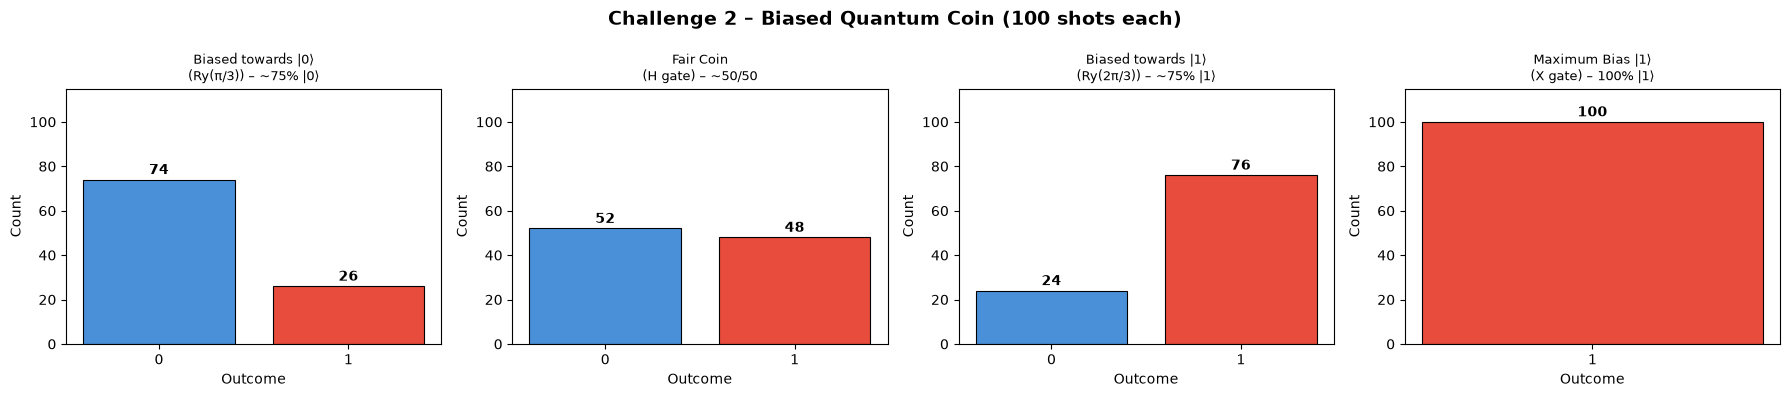

Histogram saved as challenge2_results.png


In [8]:
# ── Challenge 2 – Bonus: Different degrees of bias ───────────────────────
# Circuit using X gate alone: 100% |1⟩
qc_max1 = QuantumCircuit(1, 1)
qc_max1.x(0)
qc_max1.measure(0, 0)
counts_max1 = run_circuit(qc_max1)

# Fair coin (H gate) for reference
qc_fair = QuantumCircuit(1, 1)
qc_fair.h(0)
qc_fair.measure(0, 0)
counts_fair = run_circuit(qc_fair)

# ── Plot all 4 bias levels ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
fig.suptitle('Challenge 2 – Biased Quantum Coin (100 shots each)', fontsize=14, fontweight='bold')

configs = [
    (counts_bias0, 'Biased towards |0⟩\n(Ry(π/3)) – ~75% |0⟩', ['#4A90D9','#E74C3C']),
    (counts_fair,  'Fair Coin\n(H gate) – ~50/50',               ['#4A90D9','#E74C3C']),
    (counts_bias1, 'Biased towards |1⟩\n(Ry(2π/3)) – ~75% |1⟩', ['#4A90D9','#E74C3C']),
    (counts_max1,  'Maximum Bias |1⟩\n(X gate) – 100% |1⟩',     ['#4A90D9','#E74C3C']),
]

for ax, (counts, title, colors) in zip(axes, configs):
    labels = sorted(counts.keys())
    values = [counts.get(k, 0) for k in labels]
    color_map = {'0': '#4A90D9', '1': '#E74C3C'}
    bar_colors = [color_map.get(l, '#888') for l in labels]
    bars = ax.bar(labels, values, color=bar_colors, edgecolor='black', linewidth=0.8)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel('Outcome')
    ax.set_ylabel('Count')
    ax.set_ylim(0, 115)
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                str(val), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('challenge2_results.png', bbox_inches='tight')
plt.show()
print('Histogram saved as challenge2_results.png')


## Challenge 2 – Explanation

**How quantum gates change the probability of obtaining 0 or 1:**

A qubit in state `|0⟩` can be visualized on the **Bloch sphere** at the north pole.
Quantum gates rotate this vector:

- **H gate** rotates to the equator → equal superposition → P(0) = P(1) = 50%.
- **Ry(θ) gate** rotates by angle θ around the Y-axis:
  - P(0) = cos²(θ/2)
  - P(1) = sin²(θ/2)
- Choosing θ < π/2 biases toward `|0⟩`; θ > π/2 biases toward `|1⟩`; θ = π gives exactly `|1⟩`.

By selecting the rotation angle, we **precisely control** the measurement probabilities.
This is the core power of quantum gates: they continuously rotate quantum states, enabling
any desired probability distribution, not just the discrete 0/1 of classical bits.

**Challenge Question Answer:** Quantum gates change measurement probabilities by rotating
the qubit's state vector on the Bloch sphere. Larger rotations increase P(1); smaller rotations
leave the qubit closer to |0⟩, increasing P(0). This is fundamentally different from classical
bits which can only be deterministically 0 or 1.


---
# Challenge 3 – Can You Change the Correlation?

**Problem Statement:** Two qubits can be prepared in a state where their measurement
outcomes are strongly correlated. Modify the Bell-state circuit and investigate
whether you can change the relationship between the two measurement outcomes.

## Strategy
The **original Bell state** is created with H + CNOT:
- State: (|00⟩ + |11⟩)/√2
- Dominant outcomes: `00` and `11` (correlated)

**Modification:** Apply an X gate to qubit 0 after creating the Bell state.
- X|00⟩ → |10⟩, X|11⟩ → |01⟩
- New state: (|01⟩ + |10⟩)/√2
- Dominant outcomes switch to `01` and `10` (anti-correlated)

## Predictions
| Circuit | Expected Dominant Outcomes | Other Outcomes |
|---------|--------------------------|---------------|
| Original Bell | `00`, `11` | `01`, `10` very rare |
| Modified (X on q0) | `01`, `10` | `00`, `11` very rare |


In [9]:
# ── Challenge 3 – Original Bell State Circuit ────────────────────────────
print('=== Challenge 3: Can You Change the Correlation? ===')
print()

print('PREDICTION – Original Bell State:')
print('  State = (|00⟩ + |11⟩)/√2')
print('  Dominant outcomes: 00 and 11 (both qubits always agree)')
print('  Expected: ~50 counts of "00", ~50 counts of "11", 0 for "01" or "10"')

qc_bell = QuantumCircuit(2, 2)
qc_bell.h(0)        # Superposition on qubit 0
qc_bell.cx(0, 1)    # CNOT: entangle qubit 1 with qubit 0
qc_bell.measure([0, 1], [0, 1])

print('\nOriginal Bell State Circuit:')
print(qc_bell.draw(output='text'))
counts_bell = run_circuit(qc_bell)
print(f'\nResults: {counts_bell}')


=== Challenge 3: Can You Change the Correlation? ===

PREDICTION – Original Bell State:
  State = (|00⟩ + |11⟩)/√2
  Dominant outcomes: 00 and 11 (both qubits always agree)
  Expected: ~50 counts of "00", ~50 counts of "11", 0 for "01" or "10"

Original Bell State Circuit:
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 



Results: {'00': 52, '11': 48}


In [10]:
# ── Challenge 3 – Modified Circuit (X gate added to qubit 0) ─────────────
print('PREDICTION – Modified Circuit (add X on qubit 0 after Bell state):')
print('  Applying X to qubit 0 flips: |00⟩ → |10⟩, |11⟩ → |01⟩')
print('  New state = (|10⟩ + |01⟩)/√2')
print('  Dominant outcomes: 01 and 10 (qubits now always disagree)')
print('  Expected: ~50 counts of "01", ~50 counts of "10", 0 for "00" or "11"')

qc_bell_mod = QuantumCircuit(2, 2)
qc_bell_mod.h(0)        # Superposition on qubit 0
qc_bell_mod.cx(0, 1)    # CNOT: entangle
qc_bell_mod.x(0)        # ADD: X gate on qubit 0 (the ONE modification)
qc_bell_mod.measure([0, 1], [0, 1])

print('\nModified Bell State Circuit (X gate added):')
print(qc_bell_mod.draw(output='text'))
counts_bell_mod = run_circuit(qc_bell_mod)
print(f'\nResults: {counts_bell_mod}')


PREDICTION – Modified Circuit (add X on qubit 0 after Bell state):
  Applying X to qubit 0 flips: |00⟩ → |10⟩, |11⟩ → |01⟩
  New state = (|10⟩ + |01⟩)/√2
  Dominant outcomes: 01 and 10 (qubits now always disagree)
  Expected: ~50 counts of "01", ~50 counts of "10", 0 for "00" or "11"

Modified Bell State Circuit (X gate added):
     ┌───┐     ┌───┐┌─┐
q_0: ┤ H ├──■──┤ X ├┤M├
     └───┘┌─┴─┐└┬─┬┘└╥┘
q_1: ─────┤ X ├─┤M├──╫─
          └───┘ └╥┘  ║ 
c: 2/════════════╩═══╩═
                 1   0 



Results: {'10': 56, '01': 44}


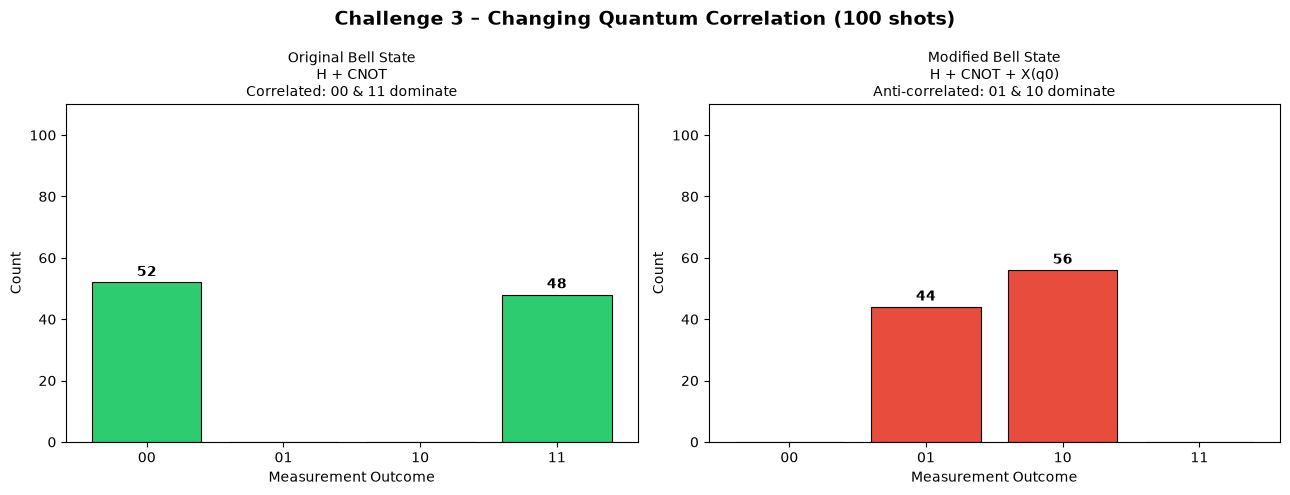

Histogram saved as challenge3_results.png


In [11]:
# ── Challenge 3 – Comparison Histograms ──────────────────────────────────
all_outcomes = ['00', '01', '10', '11']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Challenge 3 – Changing Quantum Correlation (100 shots)', fontsize=14, fontweight='bold')

colors = ['#2ECC71', '#E74C3C', '#E74C3C', '#2ECC71']  # green for dominant outcomes

# Original Bell State
ax = axes[0]
vals = [counts_bell.get(k, 0) for k in all_outcomes]
bars = ax.bar(all_outcomes, vals,
              color=['#2ECC71','#cccccc','#cccccc','#2ECC71'],
              edgecolor='black', linewidth=0.8)
ax.set_title('Original Bell State\nH + CNOT\nCorrelated: 00 & 11 dominate', fontsize=10)
ax.set_xlabel('Measurement Outcome'); ax.set_ylabel('Count')
ax.set_ylim(0, 110)
for bar, val in zip(bars, vals):
    if val > 0:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                str(val), ha='center', va='bottom', fontweight='bold')

# Modified Bell State
ax = axes[1]
vals_mod = [counts_bell_mod.get(k, 0) for k in all_outcomes]
bars_mod = ax.bar(all_outcomes, vals_mod,
                  color=['#cccccc','#E74C3C','#E74C3C','#cccccc'],
                  edgecolor='black', linewidth=0.8)
ax.set_title('Modified Bell State\nH + CNOT + X(q0)\nAnti-correlated: 01 & 10 dominate', fontsize=10)
ax.set_xlabel('Measurement Outcome'); ax.set_ylabel('Count')
ax.set_ylim(0, 110)
for bar, val in zip(bars_mod, vals_mod):
    if val > 0:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                str(val), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('challenge3_results.png', bbox_inches='tight')
plt.show()
print('Histogram saved as challenge3_results.png')


## Challenge 3 – Explanation of Observed Change

**Original Bell state** `(|00⟩ + |11⟩)/√2`:
Both qubits are **correlated** – if qubit 0 is `0`, qubit 1 is also `0`, and vice versa.
This is the signature of **quantum entanglement**.

**After adding X gate to qubit 0:**
The X gate flips qubit 0: `|0⟩→|1⟩, |1⟩→|0⟩`.
The entangled state transforms:
- `|00⟩ → |10⟩`
- `|11⟩ → |01⟩`

New state: `(|01⟩ + |10⟩)/√2` — an **anti-correlated** Bell state (Ψ⁺).

**Conclusion:** Adding a single X gate flipped the correlation from **correlated** (00/11)
to **anti-correlated** (01/10). The qubits are still entangled, but now they always
disagree instead of always agreeing. This shows how a single local gate can change
the measurement relationship between entangled qubits.


---
# Challenge 4 – Quantum Correlation Switch

**Problem Statement:** Design circuits that **switch** between correlated and
opposite measurement outcomes using only a small number of quantum gates.

## Design Overview
| Part | Circuit | Expected Dominant Outcomes |
|------|---------|---------------------------|
| A – Correlated | H + CNOT (standard Bell state) | `00`, `11` |
| B – Opposite | H + CNOT + X(q0) (modified Bell) | `01`, `10` |

### Predictions
**Part A:** Since H|0⟩ creates superposition and CNOT entangles, the result is
`(|00⟩ + |11⟩)/√2`. Both qubits always agree → `00` and `11` dominate.

**Part B:** Applying X to qubit 0 after entanglement creates `(|10⟩ + |01⟩)/√2`.
The qubits always disagree → `01` and `10` dominate.


In [12]:
# ── Challenge 4 – Part A: Correlated Outcomes (00 and 11) ───────────────
print('=== Challenge 4: Quantum Correlation Switch ===')
print()

print('--- Part A: Correlated Outcomes ---')
print('PREDICTION: H + CNOT creates Bell state (|00⟩ + |11⟩)/√2')
print('  Dominant outcomes: 00 and 11 (qubits always match)')
print('  Expected: ~50 counts of "00", ~50 counts of "11"')

# Part A Circuit: Standard Bell State
qc_partA = QuantumCircuit(2, 2)
qc_partA.h(0)         # Gate 1: H on qubit 0
qc_partA.cx(0, 1)     # Gate 2: CNOT (control=0, target=1)
qc_partA.measure([0, 1], [0, 1])

print('\nPart A Circuit:')
print(qc_partA.draw(output='text'))
counts_A4 = run_circuit(qc_partA)
print(f'\nResults (100 shots): {counts_A4}')


=== Challenge 4: Quantum Correlation Switch ===

--- Part A: Correlated Outcomes ---
PREDICTION: H + CNOT creates Bell state (|00⟩ + |11⟩)/√2
  Dominant outcomes: 00 and 11 (qubits always match)
  Expected: ~50 counts of "00", ~50 counts of "11"

Part A Circuit:
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 



Results (100 shots): {'11': 56, '00': 44}


In [13]:
# ── Challenge 4 – Part B: Opposite Outcomes (01 and 10) ─────────────────
print('--- Part B: Opposite Outcomes ---')
print('PREDICTION: H + CNOT + X(q0) creates (|10⟩ + |01⟩)/√2')
print('  Dominant outcomes: 01 and 10 (qubits always differ)')
print('  Expected: ~50 counts of "01", ~50 counts of "10"')

# Part B Circuit: Bell State with X flip on qubit 0
qc_partB = QuantumCircuit(2, 2)
qc_partB.h(0)         # Gate 1: H on qubit 0
qc_partB.cx(0, 1)     # Gate 2: CNOT
qc_partB.x(0)         # Gate 3: X flips qubit 0 (switches correlation)
qc_partB.measure([0, 1], [0, 1])

print('\nPart B Circuit:')
print(qc_partB.draw(output='text'))
counts_B4 = run_circuit(qc_partB)
print(f'\nResults (100 shots): {counts_B4}')


--- Part B: Opposite Outcomes ---
PREDICTION: H + CNOT + X(q0) creates (|10⟩ + |01⟩)/√2
  Dominant outcomes: 01 and 10 (qubits always differ)
  Expected: ~50 counts of "01", ~50 counts of "10"

Part B Circuit:
     ┌───┐     ┌───┐┌─┐
q_0: ┤ H ├──■──┤ X ├┤M├
     └───┘┌─┴─┐└┬─┬┘└╥┘
q_1: ─────┤ X ├─┤M├──╫─
          └───┘ └╥┘  ║ 
c: 2/════════════╩═══╩═
                 1   0 



Results (100 shots): {'01': 51, '10': 49}


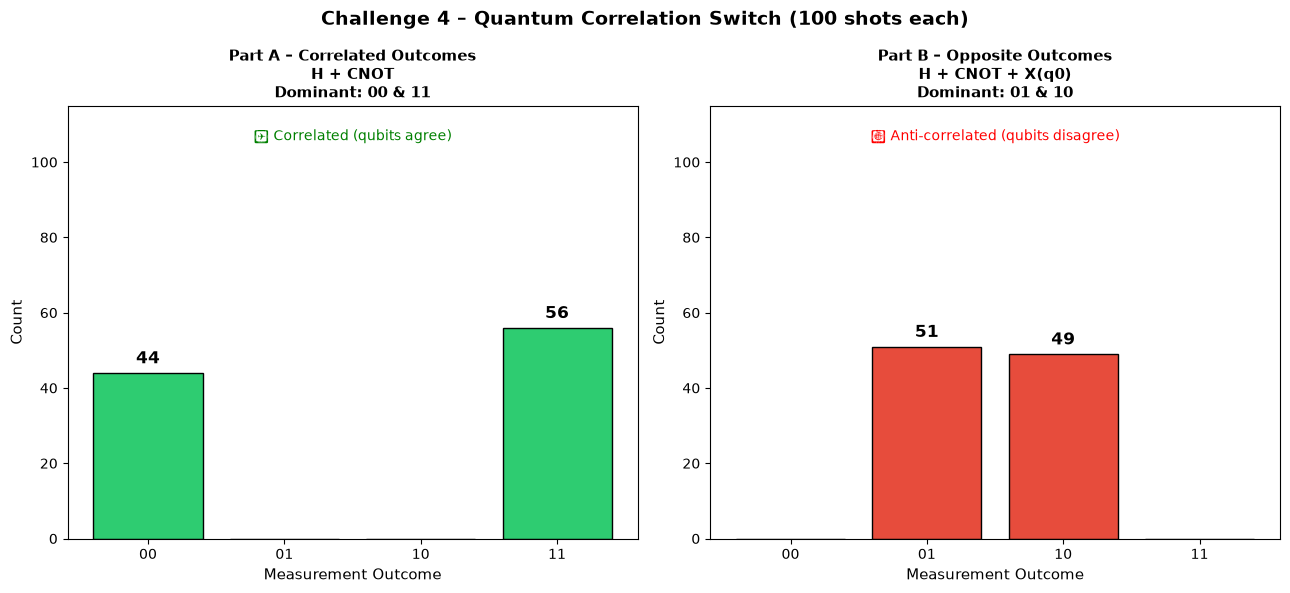

Histogram saved as challenge4_results.png


In [14]:
# ── Challenge 4 – Part C: Comparison Histograms ─────────────────────────
all_outcomes = ['00', '01', '10', '11']

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
fig.suptitle('Challenge 4 – Quantum Correlation Switch (100 shots each)', fontsize=14, fontweight='bold')

# Part A
ax = axes[0]
vals_A = [counts_A4.get(k, 0) for k in all_outcomes]
colors_A = ['#2ECC71', '#BDC3C7', '#BDC3C7', '#2ECC71']
bars_A = ax.bar(all_outcomes, vals_A, color=colors_A, edgecolor='black', linewidth=1)
ax.set_title('Part A – Correlated Outcomes\nH + CNOT\nDominant: 00 & 11', fontsize=11, fontweight='bold')
ax.set_xlabel('Measurement Outcome', fontsize=11)
ax.set_ylabel('Count', fontsize=11)
ax.set_ylim(0, 115)
for bar, val, label in zip(bars_A, vals_A, all_outcomes):
    if val > 0:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
                str(val), ha='center', va='bottom', fontweight='bold', fontsize=12)
ax.text(0.5, 0.92, '✅ Correlated (qubits agree)', transform=ax.transAxes,
        ha='center', fontsize=10, color='green')

# Part B
ax = axes[1]
vals_B = [counts_B4.get(k, 0) for k in all_outcomes]
colors_B = ['#BDC3C7', '#E74C3C', '#E74C3C', '#BDC3C7']
bars_B = ax.bar(all_outcomes, vals_B, color=colors_B, edgecolor='black', linewidth=1)
ax.set_title('Part B – Opposite Outcomes\nH + CNOT + X(q0)\nDominant: 01 & 10', fontsize=11, fontweight='bold')
ax.set_xlabel('Measurement Outcome', fontsize=11)
ax.set_ylabel('Count', fontsize=11)
ax.set_ylim(0, 115)
for bar, val, label in zip(bars_B, vals_B, all_outcomes):
    if val > 0:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
                str(val), ha='center', va='bottom', fontweight='bold', fontsize=12)
ax.text(0.5, 0.92, '🔄 Anti-correlated (qubits disagree)', transform=ax.transAxes,
        ha='center', fontsize=10, color='red')

plt.tight_layout()
plt.savefig('challenge4_results.png', bbox_inches='tight')
plt.show()
print('Histogram saved as challenge4_results.png')


In [15]:
# ── Challenge 4 – Detailed Summary Output ────────────────────────────────
print('=== Challenge 4 – Summary ===')
print()
print('Part A Results:', counts_A4)
print('Part B Results:', counts_B4)
print()

# Dominant outcomes analysis
print('--- Analysis ---')
dominant_A = sorted(counts_A4.items(), key=lambda x: x[1], reverse=True)[:2]
dominant_B = sorted(counts_B4.items(), key=lambda x: x[1], reverse=True)[:2]
print(f'Part A dominant outcomes: {[o for o, _ in dominant_A]}')
print(f'Part B dominant outcomes: {[o for o, _ in dominant_B]}')
print()
print('What changed between circuits:')
print('  Part A: 2 gates (H, CNOT)       → Correlated Bell state |Φ+⟩')
print('  Part B: 3 gates (H, CNOT, X(q0))→ Anti-correlated Bell state |Ψ+⟩')
print()
print('The single additional X gate on qubit 0 flipped the correlation type!')


=== Challenge 4 – Summary ===

Part A Results: {'11': 56, '00': 44}
Part B Results: {'01': 51, '10': 49}

--- Analysis ---
Part A dominant outcomes: ['11', '00']
Part B dominant outcomes: ['01', '10']

What changed between circuits:
  Part A: 2 gates (H, CNOT)       → Correlated Bell state |Φ+⟩
  Part B: 3 gates (H, CNOT, X(q0))→ Anti-correlated Bell state |Ψ+⟩

The single additional X gate on qubit 0 flipped the correlation type!


## Challenge 4 – Explanation

### Part A – Correlated Outcomes
**Dominant outcomes: `00` and `11`**

The circuit H + CNOT creates the **Bell state Φ⁺**:
```
|Φ+⟩ = (|00⟩ + |11⟩) / √2
```
The two qubits are quantum-entangled. When measured, they always **agree**:
if qubit 0 is `0`, qubit 1 is also `0`; if qubit 0 is `1`, qubit 1 is also `1`.

### Part B – Opposite Outcomes
**Dominant outcomes: `01` and `10`**

Adding X to qubit 0 after CNOT transforms the Bell state:
```
|Φ+⟩ = (|00⟩ + |11⟩)/√2  →  X on q0  →  (|10⟩ + |01⟩)/√2 = |Ψ+⟩
```
Now the qubits always **disagree** – if qubit 0 is `0`, qubit 1 must be `1`, and vice versa.

### Why Does This Work?
The X gate is a **local operation** on a single qubit, but because the qubits are
**entangled**, the local flip changes the *global* correlation of the two-qubit system.
This is the essence of quantum entanglement: local operations can change non-local correlations.

### Summary Table
| | Part A | Part B |
|-|--------|--------|
| Gates | H, CNOT | H, CNOT, X(q0) |
| State | `(|00⟩+|11⟩)/√2` | `(|01⟩+|10⟩)/√2` |
| Type | Correlated (Φ⁺) | Anti-correlated (Ψ⁺) |
| Dominant | `00`, `11` | `01`, `10` |
| All 4 outcomes? | No — only `00` and `11` | No — only `01` and `10` |
| Why? | Entanglement makes qubits mimic each other | X flip inverts one qubit's outcome |


---
# Overall Summary – All 4 Challenges Complete

| Challenge | Topic | Key Concept Demonstrated |
|-----------|-------|-------------------------|
| 1 | Predict the Output | X gate flips, XX = identity, H creates superposition |
| 2 | Biased Quantum Coin | Ry(θ) rotates qubit to any desired probability |
| 3 | Change the Correlation | X gate converts correlated ↔ anti-correlated Bell states |
| 4 | Correlation Switch | Single X gate switches between Φ⁺ and Ψ⁺ Bell states |

**Gates used:** X, H, Ry(θ), CNOT — all fundamental single- and two-qubit gates.

*Qiskit Fall Fest 2026 – Vishnu Institute of Technology*
